In [1]:
%load_ext autoreload
%autoreload 2

In [38]:
from credit_card_default.config import load_config, PROJECT_ROOT

cfg = load_config()
RANDOM_STATE = cfg["random_state"]
N_SPLITS = cfg["cv"]["n_splits"]
print(RANDOM_STATE, N_SPLITS)   

42 5


In [2]:
from credit_card_default.features import make_prep
from credit_card_default.data import clean, load_credit, split_data

df = clean(load_credit())
X_train, X_test, y_train, y_test = split_data(df)

print(X_train.shape, X_test.shape)

(24000, 23) (6000, 23)


In [16]:
from credit_card_default.models import get_model, build_pipeline, compare_models

dict_models = get_model(RANDOM_STATE)
pipelines = {name: build_pipeline(make_prep(),model) for name, model in dict_models.items()}

print(dict_models)
print(type(pipelines["dummy"]))

{'dummy': DummyClassifier(), 'logistic_regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42), 'knn': KNeighborsClassifier(n_neighbors=50), 'linear_svm': LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)}
<class 'sklearn.pipeline.Pipeline'>


In [17]:
from credit_card_default.evaluate import cross_validate_model
import pandas as pd 

cv_dummy = cross_validate_model(pipelines["dummy"], X_train, y_train, N_SPLITS, RANDOM_STATE)
pd.DataFrame(cv_dummy).T.round(4)



c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,mean,std
pr_auc,0.2212,0.0001
roc_auc,0.5000,0.0000


In [18]:
from credit_card_default.models import compare_models

comparison_table = compare_models(pipelines, X_train, y_train, N_SPLITS, RANDOM_STATE) 
(comparison_table.sort_values("pr_auc_mean", ascending=False)
      .round(3)
      .style.format({"time_s": "{:.1f}"})
      .background_gradient(subset=["pr_auc_mean"], cmap="Blues"))

c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserW

,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,time_s,pr_auc_gain_vs_dummy
model,,,,,,
logistic_regression,0.542000,0.012000,0.770000,0.006000,1.3,0.321000
linear_svm,0.539000,0.013000,0.767000,0.006000,1.9,0.318000
knn,0.509000,0.017000,0.752000,0.012000,1.6,0.288000
dummy,0.221000,0.000000,0.500000,0.000000,0.3,0.000000


c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserW

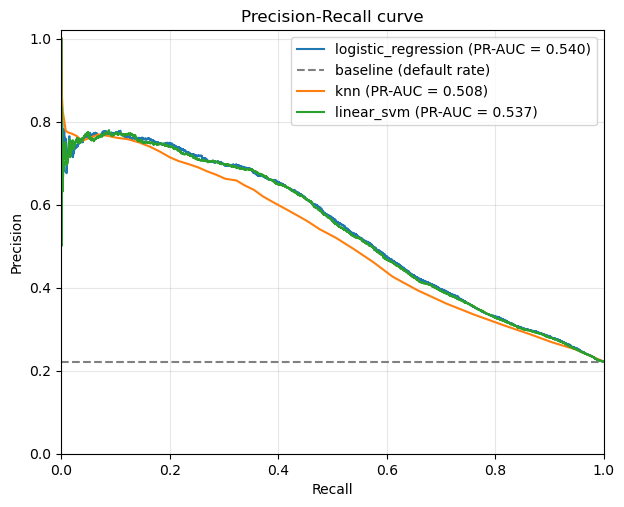

In [19]:
import matplotlib.pyplot as plt
from pathlib import Path
from credit_card_default.evaluate import get_oof_scores, plot_pr_curve

fig, ax = plt.subplots(figsize=(7, 5.5))
oof = {}  # keep the scores: you will reuse them tomorrow to choose the threshold

for name, pipe in pipelines.items():
    if name == "dummy":
        continue  # the gray dashed baseline already represents it
    oof[name] = get_oof_scores(pipe, X_train, y_train, N_SPLITS, RANDOM_STATE)
    plot_pr_curve(y_train, oof[name], label=name, ax=ax)

Path("../reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../reports/figures/pr_curves_models.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
from credit_card_default.models import get_param_grid, tune_model

tuned = {"dummy": pipelines["dummy"]}  
best_params = {}

for name in ["logistic_regression", "linear_svm", "knn"]:
    grid = get_param_grid(name, cfg["param_grids"])
    tuned[name], best_params[name] = tune_model(
        pipelines[name], grid, X_train, y_train, N_SPLITS, RANDOM_STATE)
    print(name, best_params[name])

logistic_regression {'model__C': 1}
linear_svm {'model__C': 0.1}
knn {'model__n_neighbors': 50, 'model__weights': 'distance'}


In [28]:
table_default = comparison_table
table_tuned = compare_models(tuned, X_train, y_train, N_SPLITS, RANDOM_STATE)
comparison = table_default[["pr_auc_mean", "roc_auc_mean", "time_s"]].join(
    table_tuned[["pr_auc_mean", "roc_auc_mean", "time_s"]],
    lsuffix="_default", rsuffix="_tuned")
comparison["pr_auc_delta"] = comparison["pr_auc_mean_tuned"] - comparison["pr_auc_mean_default"]
comparison.round(3)

c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserW

,pr_auc_mean_default,roc_auc_mean_default,time_s_default,pr_auc_mean_tuned,roc_auc_mean_tuned,time_s_tuned,pr_auc_delta
model,,,,,,,
dummy,0.221,0.500,0.287,0.221,0.500,0.581,0.000
logistic_regression,0.542,0.770,1.346,0.542,0.770,2.332,0.000
knn,0.509,0.752,1.594,0.512,0.751,1.827,0.003
linear_svm,0.539,0.767,1.869,0.539,0.768,2.749,0.000


In [29]:
final_model = tuned["logistic_regression"]   
oof = get_oof_scores(final_model, X_train, y_train, N_SPLITS, RANDOM_STATE)

c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\johna\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [35]:
from credit_card_default.evaluate import compute_metrics, find_best_threshold
import numpy as np
import pandas as pd 


rules = {
    "default (0.5)":   0.5,
    "best F1":         find_best_threshold(y_train, oof, metric="f1"),
    "min recall 0.60": find_best_threshold(y_train, oof, metric="min_recall", min_recall=0.60),
    "min recall 0.70": find_best_threshold(y_train, oof, metric="min_recall", min_recall=0.70),
}

rows = []
for rule, t in rules.items():
    m = compute_metrics(y_train, oof, t)
    rows.append({
        "rule": rule,
        "threshold": t,
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1"],
        "flagged_share": (np.asarray(oof) >= t).mean(),   # % of clients flagged as defaulters
    })

threshold_table = pd.DataFrame(rows).set_index("rule")
threshold_table.round(3)

,threshold,precision,recall,f1,flagged_share
rule,,,,,
default (0.5),0.500,0.495,0.580,0.534,0.259
best F1,0.518,0.510,0.565,0.536,0.245
min recall 0.60,0.480,0.475,0.600,0.530,0.279
min recall 0.70,0.410,0.396,0.700,0.506,0.391


The best f1 score and the minimum recall at 60% give us similar precision and recall. We are going to choose the minimimum threshold at 60% since we want to avoid as much as possible flagging true future defaulters as non-defaulters, while still being able to raise true alarms and thus keep false positives low as well. It's a good trade off. 

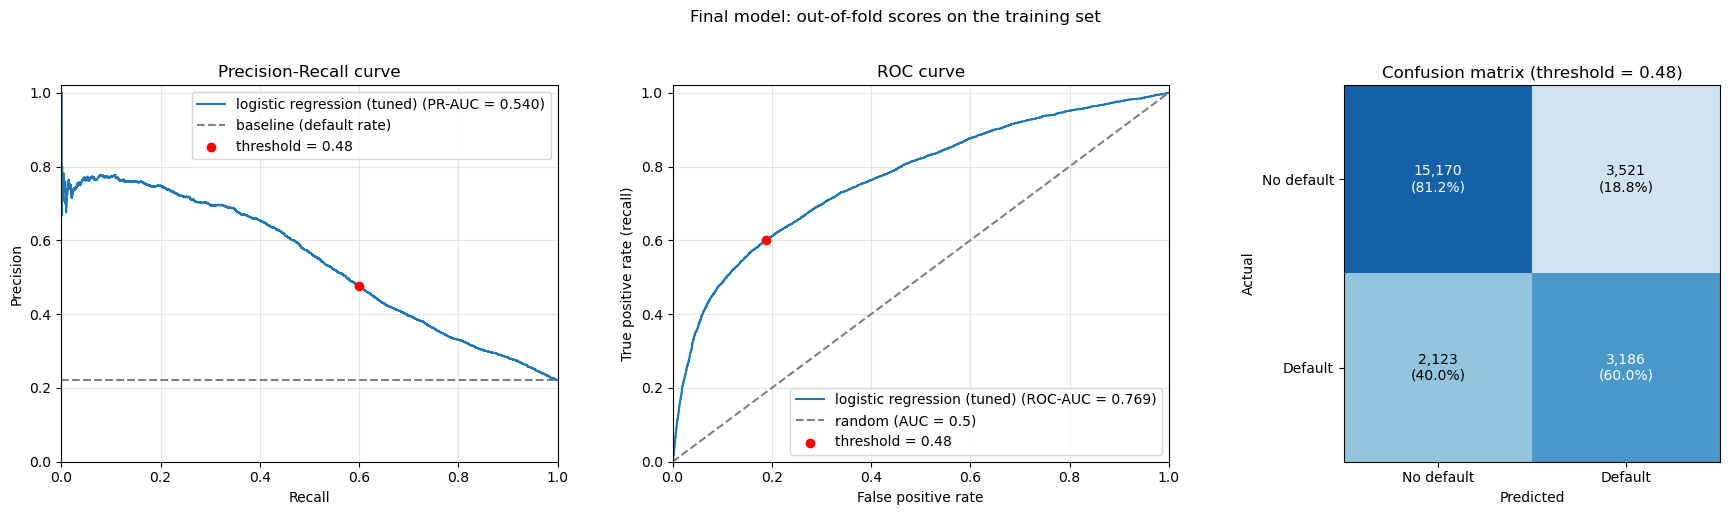

,threshold = 0.480
precision,0.475
recall,0.600
f1,0.530
roc_auc,0.769
pr_auc,0.540


In [39]:
from credit_card_default.evaluate import plot_pr_curve, plot_roc_curve, plot_confusion_matrix
import matplotlib.pyplot as plt

threshold = find_best_threshold(
    y_train, oof,
    metric=cfg["evaluation"]["threshold_metric"],
    min_recall=cfg["evaluation"]["min_recall"],
)

fig_dir = PROJECT_ROOT / cfg["paths"]["figures_dir"]
fig_dir.mkdir(parents=True, exist_ok=True)

label = "logistic regression (tuned)"
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_pr_curve(y_train, oof, label=label, threshold=threshold, ax=axes[0])
plot_roc_curve(y_train, oof, label=label, threshold=threshold, ax=axes[1])
plot_confusion_matrix(y_train, oof, threshold=threshold, ax=axes[2])
fig.suptitle("Final model: out-of-fold scores on the training set", y=1.02)
fig.tight_layout()
fig.savefig(fig_dir / "final_model_train_oof.png", dpi=150, bbox_inches="tight")
plt.show()


pd.Series(compute_metrics(y_train, oof, threshold)).round(3).to_frame(f"threshold = {threshold:.3f}")


In [40]:
import numpy as np
from credit_card_default.models import save_model, load_model

model_path = PROJECT_ROOT / cfg["paths"]["models_dir"] / "final_model.joblib"
save_model(final_model, threshold, model_path)  
print("saved to:", model_path)


loaded_model, loaded_threshold = load_model(model_path)
same_scores = np.allclose(
    loaded_model.predict_proba(X_train)[:, 1],
    final_model.predict_proba(X_train)[:, 1],
)
print("same threshold:", loaded_threshold == threshold, "| same predictions:", same_scores)

saved to: C:\Users\johna\Desktop\Credit Card Default Project\credit_card_default\models\final_model.joblib
same threshold: True | same predictions: True
